In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    x = torch.randn(3, 3, device="cuda")
    print("\nGPU tensor:")
    print(x)

PyTorch: 2.14.1+cu130
CUDA version: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 2060

GPU tensor:
tensor([[ 1.7811,  0.6184, -1.3535],
        [ 0.3016, -0.5350,  0.6962],
        [ 0.4760,  0.7032, -0.8357]], device='cuda:0')


In [ ]:
from pathlib import Path
import numpy as np
import torch

from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [3]:
DATA_PATH = Path("../data/processed/bloodmnist_preprocessed.npz")

with np.load(DATA_PATH) as data:
    X_train_np = data["X_train_standardized"]
    X_val_np = data["X_val_standardized"]

    y_train_np = data["y_train"]
    y_val_np = data["y_val"]

    class_names = data["class_names"]

print("Training:", X_train_np.shape)
print("Validation:", X_val_np.shape)
print("Classes:", class_names)

Training: (11943, 28, 28, 3)
Validation: (1711, 28, 28, 3)
Classes: ['basophil' 'eosinophil' 'erythroblast'
 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)'
 'lymphocyte' 'monocyte' 'neutrophil' 'platelet']


In [5]:
X_train_np = np.transpose(X_train_np, (0, 3, 1, 2)).copy()
X_val_np = np.transpose(X_val_np, (0, 3, 1, 2)).copy()

print("Training:", X_train_np.shape)
print("Validation:", X_val_np.shape)

Training: (11943, 3, 28, 28)
Validation: (1711, 3, 28, 28)


In [6]:
X_train_tensor = torch.from_numpy(X_train_np.astype(np.float32))
X_val_tensor = torch.from_numpy(X_val_np.astype(np.float32))

y_train_tensor = torch.from_numpy(y_train_np.astype(np.int64))
y_val_tensor = torch.from_numpy(y_val_np.astype(np.int64))

print("Image tensor:", X_train_tensor.shape)
print("Label tensor:", y_train_tensor.shape)
print("Image dtype:", X_train_tensor.dtype)
print("Label dtype:", y_train_tensor.dtype)

Image tensor: torch.Size([11943, 3, 28, 28])
Label tensor: torch.Size([11943])
Image dtype: torch.float32
Label dtype: torch.int64


In [ ]:
BATCH_SIZE = 128

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 94
Validation batches: 14


In [ ]:
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print("First 10 labels:", labels[:10])

Batch image shape: torch.Size([128, 3, 28, 28])
Batch label shape: torch.Size([128])
Image dtype: torch.float32
Label dtype: torch.int64
First 10 labels: tensor([4, 3, 6, 4, 2, 6, 1, 3, 1, 2])


In [ ]:
import torch.nn as nn


class BloodCellCNN(nn.Module):

    def __init__(self, num_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            
            #first convolution
            nn.Conv2d(
                in_channels=3,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            #second convolution
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(

            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p=0.3),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        x = self.features(x)

        x = torch.flatten(x, start_dim=1)

        x = self.classifier(x)

        return x


model = BloodCellCNN(
    num_classes=len(class_names)
).to(device)

print(model)

BloodCellCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Linear(in_features=3136, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=8, bias=True)
  )
)


In [13]:
model.eval()

images_gpu = images.to(device)

with torch.no_grad():
    outputs = model(images_gpu)

print("Output shape:", outputs.shape)
print("Model device:", next(model.parameters()).device)

Output shape: torch.Size([128, 8])
Model device: cuda:0


In [14]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [ ]:
# training
model.train()

running_loss = 0.0
correct = 0
total = 0

# going through all trainings-batches
for images, labels in train_loader:

    # to GPU
    images = images.to(device)
    labels = labels.to(device)

    # 1. reset old gradients
    optimizer.zero_grad()

    # 2. forecasts
    outputs = model(images)

    # 3. errors
    loss = criterion(outputs, labels)

    # 4. calculate gradients 
    loss.backward()

    # 5. update weights
    optimizer.step()

    running_loss += loss.item() * labels.size(0)

    predictions = outputs.argmax(dim=1)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)


# results
train_loss = running_loss / total
train_accuracy = correct / total

print(f"Training Loss: {train_loss:.4f}")
print(f"Training Accuracy: {train_accuracy:.4f}")

Training Loss: 0.9396
Training Accuracy: 0.6616


In [16]:
# evaluation
model.eval()

val_running_loss = 0.0
val_correct = 0
val_total = 0

# no gradient calculation during validation
with torch.no_grad():

    for images, labels in val_loader:

        # to GPU
        images = images.to(device)
        labels = labels.to(device)

        # forecasts
        outputs = model(images)

        # errors
        loss = criterion(outputs, labels)

        val_running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)
        val_correct += (predictions == labels).sum().item()
        val_total += labels.size(0)


# results
val_loss = val_running_loss / val_total
val_accuracy = val_correct / val_total

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")

Validation Loss: 0.5049
Validation Accuracy: 0.8177


In [ ]:
from pathlib import Path

# settings
EPOCHS = 15
PATIENCE = 5

# for best models
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "bloodcell_cnn_best.pth"

# history of the training
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
epochs_without_improvement = 0

for epoch in range(EPOCHS):

    # -------------------------
    # training
    # -------------------------

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = correct / total

    # -------------------------
    # validation
    # -------------------------

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = val_correct / val_total

    # -------------------------
    # results
    # -------------------------

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(f"\nEpoch [{epoch + 1}/{EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")

    # -------------------------
    # best modell
    # -------------------------

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save(model.state_dict(), BEST_MODEL_PATH)

        print("Best model saved!")

    else:

        epochs_without_improvement += 1

    # -------------------------
    # early stopping
    # -------------------------

    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered!")
        break


Epoch [1/15]
Train Loss: 0.4816
Train Accuracy: 0.8305
Validation Loss: 0.3718
Validation Accuracy: 0.8638
Best model saved!

Epoch [2/15]
Train Loss: 0.3892
Train Accuracy: 0.8603
Validation Loss: 0.3382
Validation Accuracy: 0.8854
Best model saved!

Epoch [3/15]
Train Loss: 0.3551
Train Accuracy: 0.8726
Validation Loss: 0.3095
Validation Accuracy: 0.8907
Best model saved!

Epoch [4/15]
Train Loss: 0.3050
Train Accuracy: 0.8907
Validation Loss: 0.2843
Validation Accuracy: 0.8948
Best model saved!

Epoch [5/15]
Train Loss: 0.2876
Train Accuracy: 0.8992
Validation Loss: 0.2710
Validation Accuracy: 0.9071
Best model saved!

Epoch [6/15]
Train Loss: 0.2529
Train Accuracy: 0.9068
Validation Loss: 0.2887
Validation Accuracy: 0.8960

Epoch [7/15]
Train Loss: 0.2339
Train Accuracy: 0.9164
Validation Loss: 0.2658
Validation Accuracy: 0.9030
Best model saved!

Epoch [8/15]
Train Loss: 0.2062
Train Accuracy: 0.9267
Validation Loss: 0.2414
Validation Accuracy: 0.9158
Best model saved!

Epoch [9/

In [18]:
# load the best modell
best_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True
)

model.load_state_dict(best_checkpoint)
model.eval()

print("Best model loaded successfully!")

Best model loaded successfully!


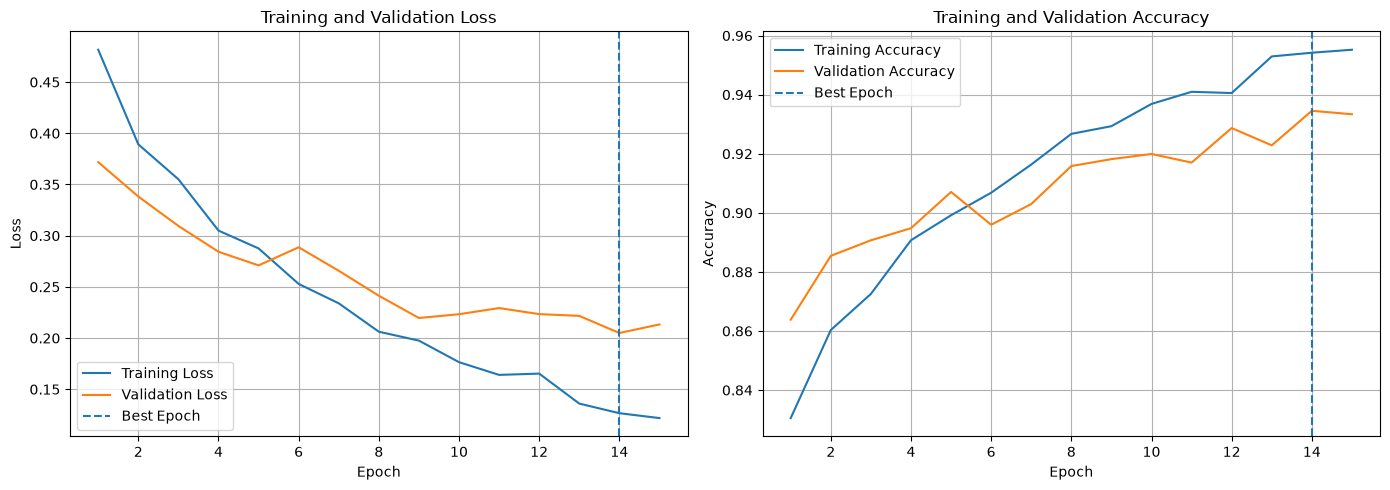

Best epoch: 14
Best validation loss: 0.2050


In [19]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

# epoche with the lowest loss
best_epoch = np.argmin(history["val_loss"]) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# loss curve
axes[0].plot(epochs, history["train_loss"], label="Training Loss")
axes[0].plot(epochs, history["val_loss"], label="Validation Loss")
axes[0].axvline(best_epoch, linestyle="--", label="Best Epoch")

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# accuracy curve
axes[1].plot(epochs, history["train_accuracy"], label="Training Accuracy")
axes[1].plot(epochs, history["val_accuracy"], label="Validation Accuracy")
axes[1].axvline(best_epoch, linestyle="--", label="Best Epoch")

axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Best epoch:", best_epoch)
print(f"Best validation loss: {min(history['val_loss']):.4f}")

In [20]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

model.eval()

all_predictions = []
all_labels = []

# go through validations data
with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())


y_val_pred_cnn = np.array(all_predictions)
y_val_true_cnn = np.array(all_labels)

# accuracy
cnn_accuracy = accuracy_score(
    y_val_true_cnn,
    y_val_pred_cnn
)

print(f"CNN Validation Accuracy: {cnn_accuracy:.4f}")

# classification report
print("\nCNN Classification Report:")

print(
    classification_report(
        y_val_true_cnn,
        y_val_pred_cnn,
        target_names=class_names,
        digits=3
    )
)

CNN Validation Accuracy: 0.9345

CNN Classification Report:
                                                                     precision    recall  f1-score   support

                                                           basophil      0.909     0.820     0.862       122
                                                         eosinophil      0.994     0.990     0.992       311
                                                       erythroblast      0.966     0.910     0.937       155
immature granulocytes(myelocytes, metamyelocytes and promyelocytes)      0.858     0.855     0.857       290
                                                         lymphocyte      0.876     0.926     0.900       122
                                                           monocyte      0.829     0.916     0.870       143
                                                         neutrophil      0.970     0.970     0.970       333
                                                           platelet

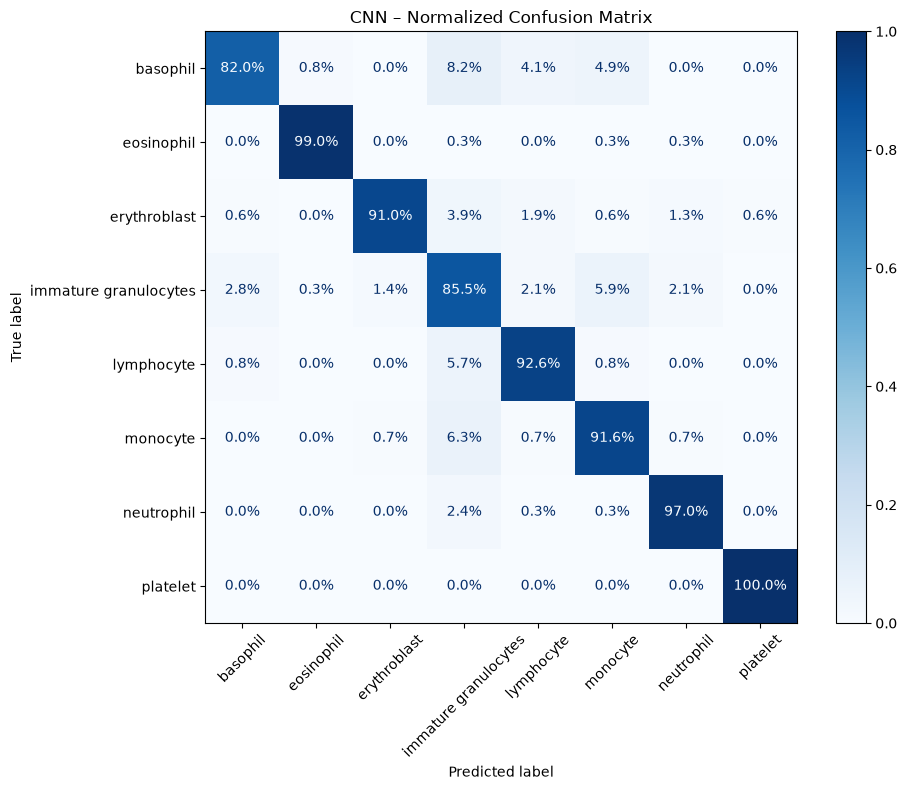

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

display_names = [
    str(name).split("(")[0].strip()
    for name in class_names
]

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_val_true_cnn,
    y_val_pred_cnn,
    display_labels=display_names,
    normalize="true",
    values_format=".1%",
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

plt.title("CNN – Normalized Confusion Matrix")
plt.tight_layout()
plt.show()

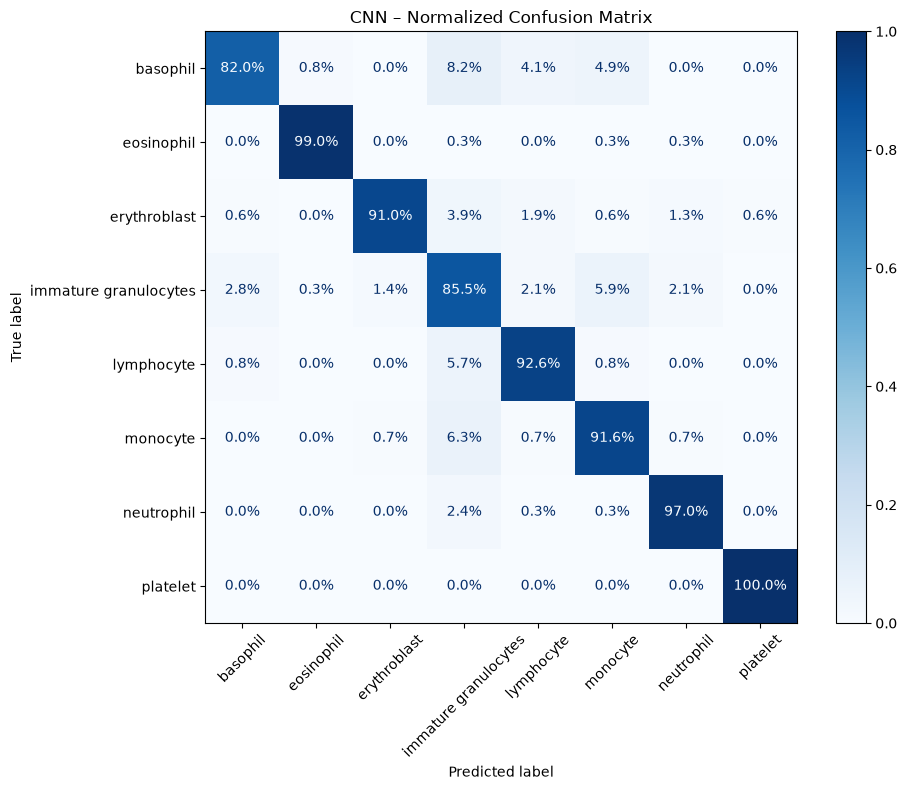

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay
from pathlib import Path

display_names = [
    str(name).split("(")[0].strip()
    for name in class_names
]

REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_val_true_cnn,
    y_val_pred_cnn,
    display_labels=display_names,
    normalize="true",
    values_format=".1%",
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

plt.title("CNN – Normalized Confusion Matrix")
plt.tight_layout()

fig.savefig(
    REPORT_DIR / "cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()